[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Agregación, relaciones entre variables y visualización efectiva.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete
**Jueves 22 de octubre de 2026 · 6:30 a 8:30 pm (CDMX)** · Módulo II: *Describir y comparar*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En esta sesión se resumirán datos por grupos (`groupby`, `pivot_table`, `crosstab`, `melt`), se medirán relaciones entre variables con las correlaciones de Pearson y Spearman sin confundir correlación con causalidad (confusores y paradoja de Simpson) y se construirán gráficas claras con *Matplotlib* y *Seaborn*. Al final se presenta la **Evaluación semanal 1**.

## 🎯 Objetivo de la sesión.

**Resumir por grupos, medir relaciones entre variables y comunicarlas con gráficas claras, sin confundir correlación con causalidad.**

Al terminar podrás:
1. Agregar con `groupby`/`agg`, `pivot_table` y `crosstab`, y cambiar entre formato ancho y largo con `melt`.
2. Calcular e interpretar las correlaciones de Pearson y Spearman y leer tablas de contingencia.
3. Reconocer confusores y la paradoja de Simpson.
4. Elegir la gráfica adecuada y cuidar escalas, facetas, color y anotaciones.

## 🗺️ Agenda (120 min).

| Min | Bloque |
|---|---|
| 10 | Repaso |
| 25 | 1. Agregación |
| 25 | 2. Relaciones entre variables |
| 30 | 3. Visualización efectiva |
| 20 | 4. Ejercicio de la sesión |
| 10 | 5. Presentación de la Evaluación semanal 1 |

🟢 = ejercicio básico · 🔴 = reto opcional

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluido el módulo `stats` de *SciPy*, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats

warnings.filterwarnings("ignore", message="vert: bool was deprecated")

**Nota:** el filtro de advertencias oculta solo un aviso interno de *Seaborn* 0.13 con *Matplotlib* 3.11 al dibujar diagramas de caja (`vert: bool was deprecated`). No afecta los resultados.

---
## 0. Repaso (10 min).

En la sesión 3 se vio que la masa y la aleta de los pingüinos se describen mal en conjunto y bien **por especie**. Hoy se formaliza esa idea: resumir por grupos y estudiar cómo se relacionan las variables. Se usarán `penguins_limpio` (se regenera si no existe) y `tips`.

* La siguiente celda leerá `penguins_limpio.csv` o lo regenerará desde `penguins.csv` si no existe.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio).astype({"species": "category", "island": "category", "sex": "category"})
pinguinos.shape

(342, 7)

`tips` registra 244 cuentas de un restaurante: `total_bill` (cuenta, en dólares), `tip` (propina), `sex` y `smoker` de quien paga, `day`, `time` (comida o cena) y `size` (personas en la mesa). Se creará la **propina porcentual** `tip_pct = 100 · tip / total_bill` y se ordenarán los días.

* La siguiente celda leerá `tips.csv`, creará `tip_pct` y convertirá `day` y `time` en categorías ordenadas.

In [3]:
propinas = (
    pd.read_csv(os.path.join(DATA, "tips.csv"))
    .assign(tip_pct=lambda d: 100 * d["tip"] / d["total_bill"])
    .astype({"day": pd.CategoricalDtype(["Thur", "Fri", "Sat", "Sun"], ordered=True),
             "time": pd.CategoricalDtype(["Lunch", "Dinner"], ordered=True)})
)
propinas.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


---
## 1. Agregación (25 min).

| Herramienta | Para qué | Resultado |
|---|---|---|
| `groupby(...).agg(...)` | Resumir una o varias columnas por grupo | Una fila por grupo |
| `pivot_table` | Resumen con un grupo en filas y otro en columnas | Tabla de doble entrada |
| `crosstab` | Conteos (o proporciones) de dos categóricas | Tabla de contingencia |
| `melt` | Pasar de formato **ancho** (una columna por variable) a **largo** (una fila por observación y variable) | Ideal para *Seaborn* y facetas |

**Nota:** en *pandas* 3, `groupby` sobre columnas categóricas usa `observed=True` por defecto: solo aparecen las combinaciones que existen en los datos.

* La siguiente celda calculará varias estadísticas de la masa por especie con **agregaciones con nombre**.

In [4]:
pinguinos.groupby("species")["body_mass_g"].agg(
    n="count",
    media="mean",
    mediana="median",
    desv_est="std",
).round(1)

,n,media,mediana,desv_est
species,,,,
Adelie,151,3700.7,3700.0,458.6
Chinstrap,68,3733.1,3700.0,384.3
Gentoo,123,5076.0,5000.0,504.1


* La siguiente celda usará `pivot_table` para la aleta media por especie (filas) y sexo (columnas), con totales.

In [5]:
pinguinos.pivot_table(index="species", columns="sex", values="flipper_length_mm",
                      aggfunc="mean", margins=True, margins_name="Total").round(1)

sex,Female,Male,Total
species,,,
Adelie,187.8,192.4,190.1
Chinstrap,191.7,199.9,195.8
Gentoo,212.7,221.5,217.2
Total,197.4,204.5,201.0


* La siguiente celda usará `crosstab` para contar pingüinos por isla y especie.

In [6]:
pd.crosstab(pinguinos["island"], pinguinos["species"], margins=True, margins_name="Total")

species,Adelie,Chinstrap,Gentoo,Total
island,,,,
Biscoe,44,0,123,167
Dream,56,68,0,124
Torgersen,51,0,0,51
Total,151,68,123,342


* La siguiente celda pasará las cuatro medidas a formato largo con `melt`.

In [7]:
largo = pinguinos.melt(id_vars=["species", "sex"], value_vars=medidas,
                       var_name="medida", value_name="valor")
largo.head(), largo.shape

(  species     sex          medida  valor
 0  Adelie    Male  bill_length_mm   39.1
 1  Adelie  Female  bill_length_mm   39.5
 2  Adelie  Female  bill_length_mm   40.3
 3  Adelie  Female  bill_length_mm   36.7
 4  Adelie    Male  bill_length_mm   39.3,
 (1368, 4))

### 🟢 Ejercicio 1 · Masa por especie y sexo.

Con agregaciones con nombre, calcula para `body_mass_g` por **especie y sexo**: `n`, `media`, `desv_est` y `mediana`. ¿En qué especie es mayor la diferencia entre machos y hembras? (pista: `unstack("sex")` y una resta).

* La siguiente celda muestra una solución posible.

In [8]:
masa_especie_sexo = pinguinos.groupby(["species", "sex"])["body_mass_g"].agg(
    n="count", media="mean", desv_est="std", mediana="median").round(1)
diferencia = masa_especie_sexo["media"].unstack("sex").assign(diferencia=lambda d: d["Male"] - d["Female"])
masa_especie_sexo, diferencia.round(1)

(                   n   media  desv_est  mediana
 species   sex                                  
 Adelie    Female  73  3368.8     269.4   3400.0
           Male    73  4043.5     346.8   4000.0
 Chinstrap Female  34  3527.2     285.3   3550.0
           Male    34  3939.0     362.1   3950.0
 Gentoo    Female  58  4679.7     281.6   4700.0
           Male    61  5484.8     313.2   5500.0,
 sex        Female    Male  diferencia
 species                              
 Adelie     3368.8  4043.5       674.7
 Chinstrap  3527.2  3939.0       411.8
 Gentoo     4679.7  5484.8       805.1)

**✅ Respuesta sugerida:**

En las tres especies los machos pesan más. La diferencia es mayor en Gentoo (≈ 805 g) que en Adelie (≈ 675 g) y Chinstrap (≈ 412 g).

### 🟢 Ejercicio 2 · Proporciones con `crosstab`.

1. Calcula la proporción de cada especie **dentro de cada isla** (`normalize="index"`) y la proporción de cada isla **dentro de cada especie** (`normalize="columns"`). ¿Qué pregunta responde cada tabla?
2. ¿Por qué no se puede comparar "la masa media por isla" sin pensar en la especie?

* La siguiente celda muestra una solución posible.

In [9]:
por_isla = pd.crosstab(pinguinos["island"], pinguinos["species"], normalize="index").round(2)
por_especie = pd.crosstab(pinguinos["island"], pinguinos["species"], normalize="columns").round(2)
por_isla, por_especie

(species    Adelie  Chinstrap  Gentoo
 island                              
 Biscoe       0.26       0.00    0.74
 Dream        0.45       0.55    0.00
 Torgersen    1.00       0.00    0.00,
 species    Adelie  Chinstrap  Gentoo
 island                              
 Biscoe       0.29        0.0     1.0
 Dream        0.37        1.0     0.0
 Torgersen    0.34        0.0     0.0)

**✅ Respuesta sugerida:**

1. `normalize="index"` responde "en Biscoe, ¿qué fracción es de cada especie?" (Biscoe: 26% Adelie y 74% Gentoo; Torgersen: 100% Adelie). `normalize="columns"` responde "los Adelie, ¿en qué islas están?" (repartidos: 29% Biscoe, 37% Dream, 34% Torgersen); Gentoo está 100% en Biscoe y Chinstrap 100% en Dream.
2. Porque isla y especie están **confundidas**: Biscoe "pesa más" solo porque ahí están los Gentoo. Para comparar islas habría que hacerlo **dentro** de una especie que viva en varias (Adelie).

### 🟢 Ejercicio 3 · Formato largo y facetas.

Con `largo`, dibuja con `sns.catplot` un diagrama de caja de `valor` por especie, con una faceta por `medida` (`col="medida"`, `sharey=False`, `col_wrap=2`). ¿Qué medida separa mejor a los Gentoo de las otras dos especies?

* La siguiente celda muestra una solución posible.

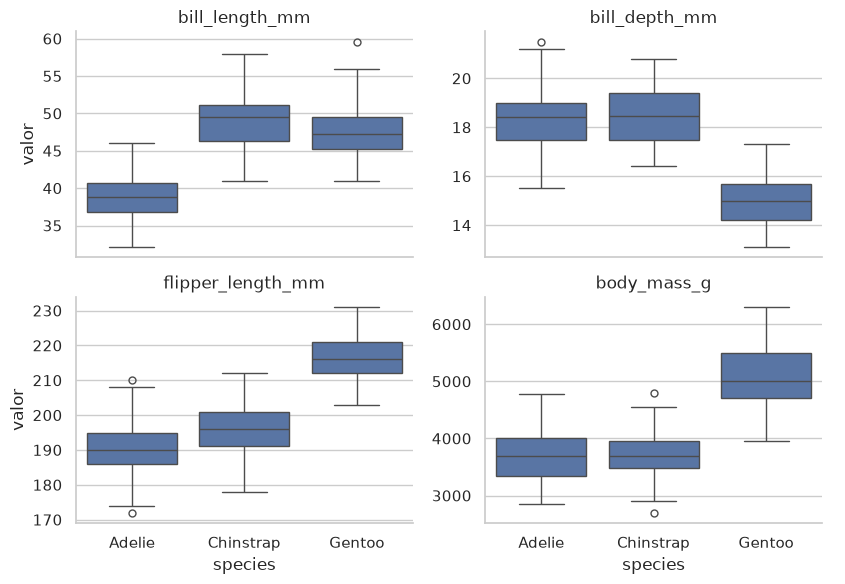

In [10]:
grafica = sns.catplot(largo, x="species", y="valor", col="medida", col_wrap=2, kind="box",
                      sharey=False, height=3, aspect=1.4)
grafica.set_titles("{col_name}")
plt.show()

**✅ Respuesta sugerida:**

La profundidad del pico (`bill_depth_mm`) y la aleta (`flipper_length_mm`) separan claramente a los Gentoo: pico menos profundo y aleta más larga, casi sin traslape. El largo del pico, en cambio, separa a los Adelie de los otros dos.

### 🔴 Reto 1 · Supervivencia en el Titanic por clase y sexo.

Con `titanic.csv`, construye con `pivot_table` la tasa de supervivencia por `class` (filas, en orden First, Second, Third) y `sex` (columnas), con márgenes. Después obtén la misma tabla con `crosstab(..., values=..., aggfunc="mean")`. ¿Qué variable parece pesar más en la supervivencia?

* La siguiente celda muestra una solución posible.

In [11]:
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
orden = ["First", "Second", "Third", "Total"]
con_pivot = titanic.pivot_table(index="class", columns="sex", values="survived", aggfunc="mean",
                                margins=True, margins_name="Total").reindex(orden).round(3)
con_crosstab = pd.crosstab(titanic["class"], titanic["sex"], values=titanic["survived"], aggfunc="mean",
                           margins=True, margins_name="Total").reindex(orden).round(3)
con_pivot, con_pivot.equals(con_crosstab)

(sex     female   male  Total
 class                       
 First    0.968  0.369  0.630
 Second   0.921  0.157  0.473
 Third    0.500  0.135  0.242
 Total    0.742  0.189  0.384,
 True)

**✅ Respuesta sugerida:**

El sexo pesa más: en todas las clases sobreviven muchas más mujeres (97%, 92% y 50%) que hombres (37%, 16% y 14%). La clase también importa, sobre todo para las mujeres: en tercera clase solo sobrevive la mitad.

---
## 2. Relaciones entre variables (25 min).

| Medida | Mide | Rango | Sensible a |
|---|---|---|---|
| **Pearson** (*r*) | Asociación **lineal** | −1 a 1 | Atípicos; relaciones no lineales |
| **Spearman** (ρ) | Asociación **monótona** (Pearson sobre los rangos) | −1 a 1 | Menos sensible a atípicos |

Ambas se calculan con `df.corr(method="pearson")` o `method="spearman"`, o con `stats.pearsonr` y `stats.spearmanr`. Para dos variables **categóricas** se usa una tabla de contingencia (y en la sesión 6, la prueba χ²).

* La siguiente celda calculará Pearson y Spearman entre la cuenta y la propina.

In [12]:
{"pearson": round(float(propinas["total_bill"].corr(propinas["tip"])), 3),
 "spearman": round(float(propinas["total_bill"].corr(propinas["tip"], method="spearman")), 3)}

{'pearson': 0.676, 'spearman': 0.679}

* La siguiente celda dibujará la relación con su recta de regresión.

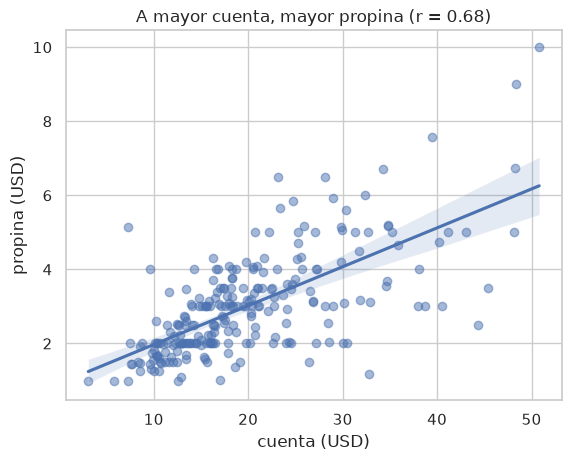

In [13]:
ax = sns.regplot(propinas, x="total_bill", y="tip", scatter_kws={"alpha": 0.5})
ax.set(xlabel="cuenta (USD)", ylabel="propina (USD)", title="A mayor cuenta, mayor propina (r = 0.68)")
plt.show()

**Ejemplo:** Pearson y Spearman difieren cuando la relación es monótona pero no lineal, o cuando hay atípicos. Se simularán ambos casos.

* La siguiente celda comparará ambas correlaciones en una relación exponencial y en datos sin relación con un solo atípico.

In [14]:
x = np.arange(1, 21, dtype=float)
exponencial = pd.DataFrame({"x": x, "y": np.exp(x / 3)})
sin_relacion = pd.DataFrame({"x": rng.normal(size=30), "y": rng.normal(size=30)})
sin_relacion.loc[30] = [8.0, 8.0]
pd.DataFrame({
    "exponencial": [exponencial.corr().iloc[0, 1], exponencial.corr("spearman").iloc[0, 1]],
    "ruido + 1 atípico": [sin_relacion.corr().iloc[0, 1], sin_relacion.corr("spearman").iloc[0, 1]],
}, index=["pearson", "spearman"]).round(2)

,exponencial,ruido + 1 atípico
pearson,0.8,0.72
spearman,1.0,-0.06


En la relación exponencial, Spearman vale 1 (la relación es perfectamente monótona) y Pearson solo 0.8 (no es lineal). En los datos sin relación, **un solo punto** lleva a Pearson a 0.72, mientras que Spearman sigue cerca de 0. Conviene calcular ambas y, sobre todo, **graficar**.

### 2.1 Correlación no es causalidad.

Una correlación puede deberse a:
* **Causalidad directa** (X causa Y).
* **Causalidad inversa** (Y causa X).
* Un **confusor**: una tercera variable Z causa ambas.
* **Selección** de la muestra o **azar**.

**Ejemplo:** se simulará un año de datos en el que la **temperatura** aumenta tanto la venta de helados como los ahogamientos. Helados y ahogamientos no se causan entre sí.

* La siguiente celda simulará 365 días de temperatura, venta de helados y ahogamientos.

In [15]:
temperatura = rng.normal(22, 6, size=365)
dias = pd.DataFrame({
    "temperatura": temperatura,
    "helados": 50 + 8 * temperatura + rng.normal(0, 20, size=365),
    "ahogamientos": rng.poisson(np.clip(0.3 * temperatura - 3, 0.1, None)),
})
dias.corr().round(2)

,temperatura,helados,ahogamientos
temperatura,1.00,0.92,0.72
helados,0.92,1.00,0.64
ahogamientos,0.72,0.64,1.00


* La siguiente celda quitará a helados y ahogamientos la parte que explica la temperatura (residuos de una recta ajustada con `np.polyfit`) y correlacionará lo que queda.

In [16]:
def residuos(y, x):
    pendiente, ordenada = np.polyfit(x, y, deg=1)
    return y - (ordenada + pendiente * x)

round(float(np.corrcoef(residuos(dias["helados"], dias["temperatura"]),
                        residuos(dias["ahogamientos"], dias["temperatura"]))[0, 1]), 2)

-0.06

Una vez descontado el efecto de la temperatura, la correlación entre helados y ahogamientos prácticamente desaparece: la temperatura era el **confusor**. Controlar por una variable significa comparar observaciones con el mismo valor de esa variable; los residuos son una forma de hacerlo y la paradoja de Simpson, a continuación, muestra otra (comparar **dentro** de cada grupo).

### 2.2 La paradoja de Simpson.

Una tendencia que aparece en todos los grupos **se invierte** (o desaparece) al juntar los grupos, porque los grupos tienen centros distintos. Es un caso extremo de confusión, y `penguins` tiene un ejemplo clásico que se resolverá en el ejercicio 5.

### 🟢 Ejercicio 4 · Matriz de correlaciones.

Calcula las matrices de Pearson y de Spearman de las cuatro medidas de `pinguinos` y dibuja la de Pearson como mapa de calor (`sns.heatmap(..., annot=True, vmin=-1, vmax=1, cmap="vlag")`). ¿Qué par está más correlacionado? ¿Hay alguna correlación negativa?

* La siguiente celda muestra una solución posible.

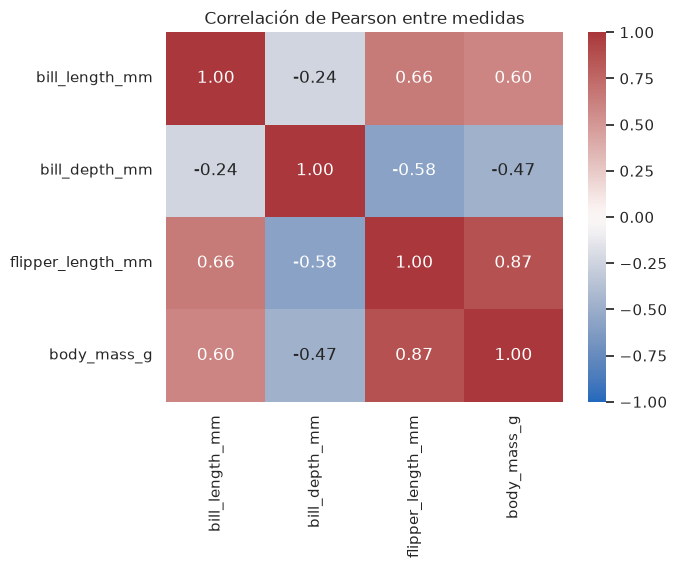

(                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
 bill_length_mm               1.00          -0.24               0.66   
 bill_depth_mm               -0.24           1.00              -0.58   
 flipper_length_mm            0.66          -0.58               1.00   
 body_mass_g                  0.60          -0.47               0.87   
 
                    body_mass_g  
 bill_length_mm            0.60  
 bill_depth_mm            -0.47  
 flipper_length_mm         0.87  
 body_mass_g               1.00  ,
                    bill_length_mm  bill_depth_mm  flipper_length_mm  \
 bill_length_mm               1.00          -0.22               0.67   
 bill_depth_mm               -0.22           1.00              -0.52   
 flipper_length_mm            0.67          -0.52               1.00   
 body_mass_g                  0.58          -0.43               0.84   
 
                    body_mass_g  
 bill_length_mm            0.58  
 bill_depth_mm            -0.43  
 fl

In [17]:
pearson = pinguinos[medidas].corr()
spearman = pinguinos[medidas].corr(method="spearman")
sns.heatmap(pearson, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag")
plt.title("Correlación de Pearson entre medidas")
plt.show()
pearson.round(2), spearman.round(2)

**✅ Respuesta sugerida:**

El par más correlacionado es aleta–masa (*r* ≈ 0.87). La profundidad del pico tiene correlaciones **negativas** con las otras tres (por ejemplo, −0.24 con el largo del pico y −0.47 con la masa). Esas correlaciones negativas son sospechosas: se revisan en el ejercicio 5.

### 🟢 Ejercicio 5 · La paradoja de Simpson en los picos.

Calcula la correlación de Pearson entre `bill_length_mm` y `bill_depth_mm`:
1. Con todos los pingüinos juntos.
2. Dentro de cada especie (pista: `groupby("species")` y `apply` con una función que calcule la correlación).

¿Qué le pasa al signo? ¿Cuál de las dos respuestas describe mejor la relación entre largo y profundidad del pico?

* La siguiente celda muestra una solución posible.

In [18]:
r_global = pinguinos["bill_length_mm"].corr(pinguinos["bill_depth_mm"])
r_especie = pinguinos.groupby("species").apply(lambda g: g["bill_length_mm"].corr(g["bill_depth_mm"]))
round(float(r_global), 3), r_especie.round(3)

(-0.235,
 species
 Adelie       0.391
 Chinstrap    0.654
 Gentoo       0.643
 dtype: float64)

**✅ Respuesta sugerida:**

Con todos juntos, *r* ≈ −0.24 (negativa: "picos más largos son menos profundos"). Dentro de **cada** especie la correlación es **positiva**: 0.39 en Adelie, 0.65 en Chinstrap y 0.64 en Gentoo. El signo se invierte porque los Gentoo tienen picos largos pero poco profundos y los Adelie, cortos pero profundos: la especie es un confusor. La descripción correcta es la **por especie**: dentro de una especie, un pico más largo tiende a ser también más profundo.

### 🔴 Reto 2 · ¿Las cuentas grandes dejan menos propina porcentual?

Calcula Pearson y Spearman entre `total_bill` y `tip_pct`, con y sin la cuenta de propina máxima (71%). Grafica la relación. ¿Qué medida es más estable? ¿Qué podría explicar la relación?

* La siguiente celda muestra una solución posible.

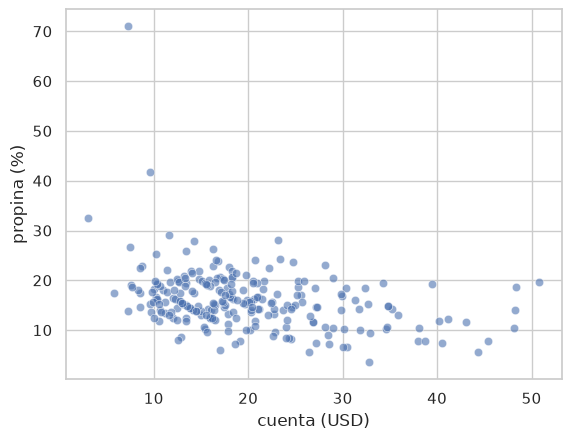

,todas,sin la máxima
pearson,-0.339,-0.352
spearman,-0.321,-0.312


In [19]:
sin_maxima = propinas.drop(index=propinas["tip_pct"].idxmax())
tabla_corr = pd.DataFrame({
    "todas": [propinas["total_bill"].corr(propinas["tip_pct"]),
              propinas["total_bill"].corr(propinas["tip_pct"], method="spearman")],
    "sin la máxima": [sin_maxima["total_bill"].corr(sin_maxima["tip_pct"]),
                      sin_maxima["total_bill"].corr(sin_maxima["tip_pct"], method="spearman")],
}, index=["pearson", "spearman"]).round(3)
ax = sns.scatterplot(propinas, x="total_bill", y="tip_pct", alpha=0.6)
ax.set(xlabel="cuenta (USD)", ylabel="propina (%)")
plt.show()
tabla_corr

**✅ Respuesta sugerida:**

Hay una relación negativa moderada (Pearson ≈ −0.34, Spearman ≈ −0.32) y casi no cambia al quitar la propina de 71%, así que ambas medidas son estables aquí. Una explicación plausible: muchas personas dejan una propina en montos redondos o con poca variación, así que, al dividir entre una cuenta mayor, el porcentaje baja. Además, `tip_pct` tiene a `total_bill` en el denominador, lo que por sí solo induce una correlación negativa. Es una asociación descriptiva, no una prueba de que las cuentas grandes "causen" propinas menores.

---
## 3. Visualización efectiva (30 min).

### 3.1 Elegir la gráfica según la pregunta.

| Pregunta | Gráficas recomendadas | Evitar |
|---|---|---|
| ¿Cómo se distribuye una variable? | Histograma, KDE, ECDF | Pastel |
| ¿Cómo se compara una numérica entre grupos? | Diagrama de caja, violín, puntos con intervalo, *strip plot* | Barras de medias sin dispersión |
| ¿Cómo se relacionan dos numéricas? | Dispersión (con color por grupo, recta o suavizado) | Líneas que unan puntos no ordenados |
| ¿Cómo se reparte un total? | Barras (apiladas o al 100%) | Pastel con muchas categorías, 3D |
| ¿Cómo cambia en el tiempo? | Líneas | Barras con muchas fechas |

### 3.2 Reglas prácticas.

* **Escalas:** las barras empiezan en cero; para datos multiplicativos, escala logarítmica.
* **Facetas** (`col=`, `row=`) en lugar de amontonar muchos grupos en un solo panel.
* **Color** con significado: una paleta cualitativa para categorías, secuencial para cantidades y divergente para valores alrededor de un centro. Mantener el mismo color para el mismo grupo en todas las gráficas y preferir paletas aptas para daltonismo.
* **Rótulos:** ejes con unidades y un **título que diga el hallazgo**, no solo las variables.
* **Anotaciones** para señalar lo importante.

### 3.3 *Matplotlib* vs. *Seaborn*.

[*Seaborn*](https://seaborn.pydata.org) produce gráficas estadísticas con poco código a partir de un *dataframe* en formato largo (agrupa, colorea, faceta y calcula intervalos). [*Matplotlib*](https://matplotlib.org) da control total de cada elemento. En la práctica se combinan: las funciones de *Seaborn* devuelven un objeto `Axes` de *Matplotlib* que se puede seguir ajustando.

**Ejemplo:** la misma información (masa media por especie) en una gráfica engañosa y en una gráfica efectiva.

* La siguiente celda dibujará ambas versiones lado a lado.

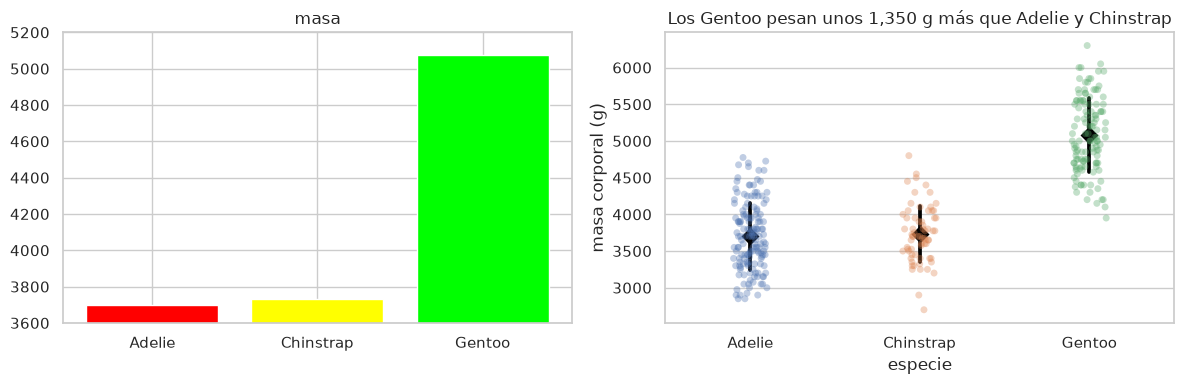

In [20]:
medias_masa = pinguinos.groupby("species")["body_mass_g"].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(medias_masa.index.astype(str), medias_masa, color=["red", "yellow", "lime"])
axes[0].set_ylim(3600, 5200)
axes[0].set_title("masa")

sns.stripplot(pinguinos, x="species", y="body_mass_g", hue="species", alpha=0.35, legend=False, ax=axes[1])
sns.pointplot(pinguinos, x="species", y="body_mass_g", color="black", linestyle="none",
              errorbar="sd", markers="D", ax=axes[1])
axes[1].set(xlabel="especie", ylabel="masa corporal (g)",
            title="Los Gentoo pesan unos 1,350 g más que Adelie y Chinstrap")
plt.tight_layout()
plt.show()

La versión de la izquierda **corta el eje** (las barras parecen indicar que Gentoo pesa varias veces más), usa colores sin significado y no tiene unidades ni título informativo. La de la derecha muestra **todos los datos**, la media con ± una desviación estándar, unidades y un título con el hallazgo.

* La siguiente celda mostrará facetas: la relación aleta–masa por isla, coloreada por especie.

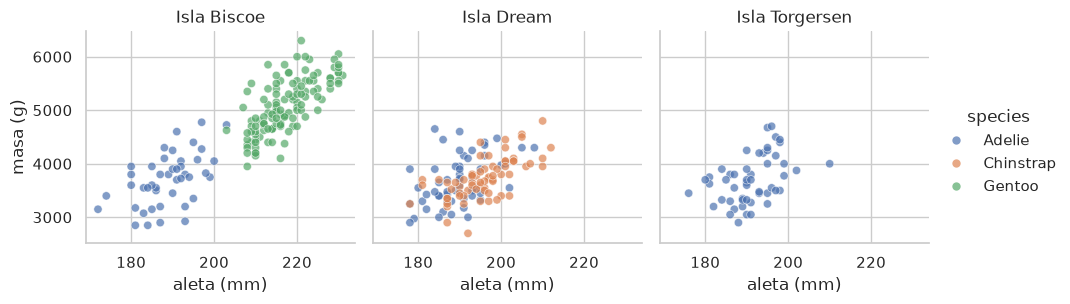

In [21]:
grafica = sns.relplot(pinguinos, x="flipper_length_mm", y="body_mass_g", hue="species", col="island",
                      height=3.2, aspect=1, alpha=0.7)
grafica.set_axis_labels("aleta (mm)", "masa (g)")
grafica.set_titles("Isla {col_name}")
plt.show()

* La siguiente celda agregará una anotación con *Matplotlib* sobre una gráfica de *Seaborn*.

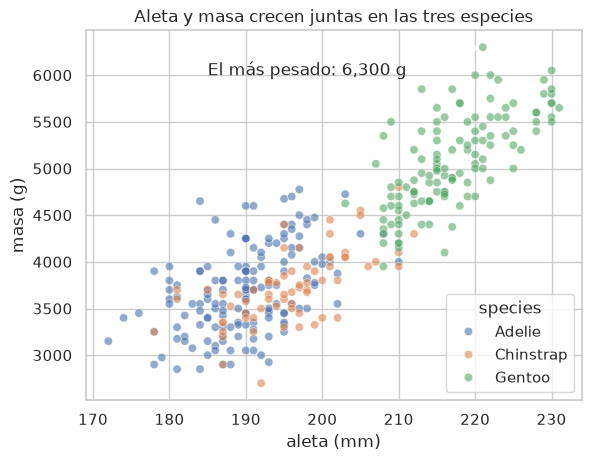

In [22]:
ax = sns.scatterplot(pinguinos, x="flipper_length_mm", y="body_mass_g", hue="species", alpha=0.6)
mas_pesado = pinguinos.loc[pinguinos["body_mass_g"].idxmax()]
ax.annotate(f"El más pesado: {mas_pesado['body_mass_g']:,} g",
            xy=(mas_pesado["flipper_length_mm"], mas_pesado["body_mass_g"]),
            xytext=(185, 6000), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="aleta (mm)", ylabel="masa (g)", title="Aleta y masa crecen juntas en las tres especies")
plt.show()

### 🔴 Reto 3 · Rescata una gráfica.

La siguiente celda dibuja una gráfica de pastel de la cantidad de pingüinos por isla y especie. Identifica al menos tres problemas y rehaz la gráfica para responder con claridad "¿qué especies hay en cada isla y cuántas?".

* La siguiente celda dibujará la gráfica de pastel original.

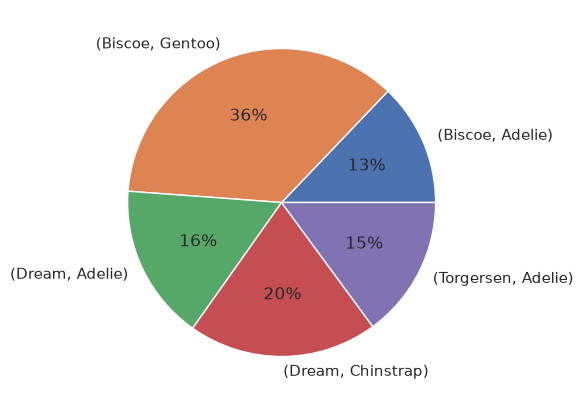

In [23]:
conteos = pinguinos.groupby(["island", "species"]).size()
conteos.plot.pie(figsize=(5, 5), autopct="%.0f%%", ylabel="")
plt.show()

* La siguiente celda muestra una solución posible.

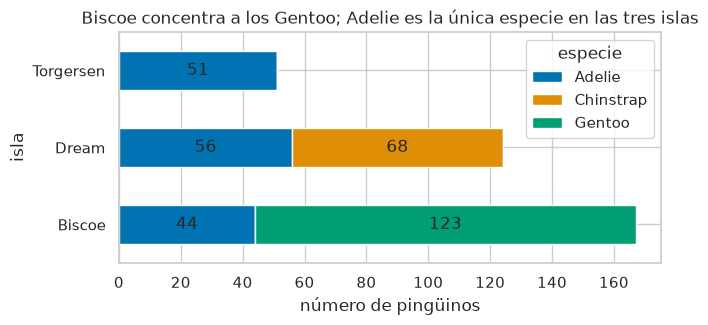

In [24]:
tabla_conteos = pd.crosstab(pinguinos["island"], pinguinos["species"])
ax = tabla_conteos.plot.barh(stacked=True, figsize=(7, 3), color=sns.color_palette("colorblind", 3))
ax.set(xlabel="número de pingüinos", ylabel="isla", title="Biscoe concentra a los Gentoo; Adelie es la única especie en las tres islas")
for contenedor in ax.containers:
    ax.bar_label(contenedor, label_type="center", fmt=lambda v: f"{v:.0f}" if v > 0 else "")
ax.legend(title="especie", bbox_to_anchor=(1, 1))
plt.show()

**✅ Respuesta sugerida:**

Problemas del pastel: (1) las etiquetas combinan isla y especie y son difíciles de leer; (2) los porcentajes son del total y ocultan los conteos; (3) es difícil comparar ángulos y sectores pequeños; (4) no hay título que diga el hallazgo. Unas barras horizontales apiladas con conteos responden directamente la pregunta.

---
## 4. Ejercicio de la sesión (20 min).

### 🟢 Ejercicio 6 · La gráfica final de la paradoja de Simpson.

Produce **una sola gráfica** que muestre la paradoja del ejercicio 5: dispersión de `bill_length_mm` vs. `bill_depth_mm` coloreada por especie, una recta por especie, la recta global (por ejemplo, negra y punteada), ejes con unidades, la correlación de cada especie y la global en la leyenda o como anotación, y un título que diga el hallazgo.

* La siguiente celda muestra una solución posible.

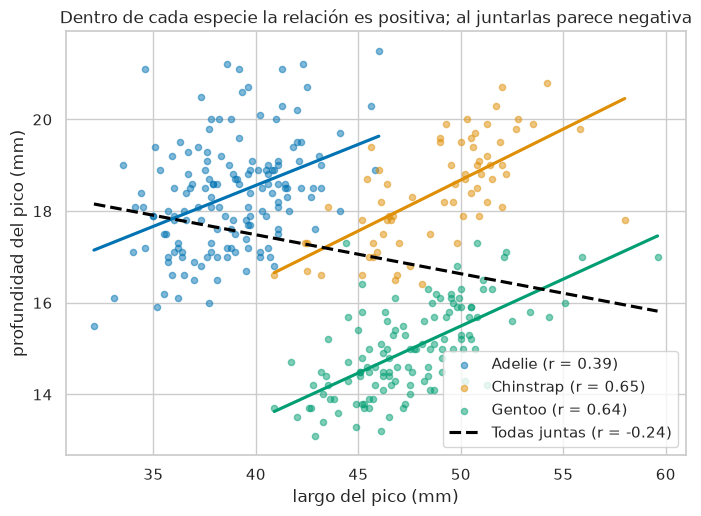

In [25]:
colores = dict(zip(pinguinos["species"].cat.categories, sns.color_palette("colorblind", 3)))
fig, ax = plt.subplots(figsize=(8, 5.5))
for especie, grupo in pinguinos.groupby("species"):
    r = grupo["bill_length_mm"].corr(grupo["bill_depth_mm"])
    sns.regplot(grupo, x="bill_length_mm", y="bill_depth_mm", ci=None, color=colores[especie],
                scatter_kws={"alpha": 0.5, "s": 20}, label=f"{especie} (r = {r:.2f})", ax=ax)
r_todos = pinguinos["bill_length_mm"].corr(pinguinos["bill_depth_mm"])
sns.regplot(pinguinos, x="bill_length_mm", y="bill_depth_mm", ci=None, scatter=False, color="black",
            line_kws={"linestyle": "--"}, label=f"Todas juntas (r = {r_todos:.2f})", ax=ax)
ax.set(xlabel="largo del pico (mm)", ylabel="profundidad del pico (mm)",
       title="Dentro de cada especie la relación es positiva; al juntarlas parece negativa")
ax.legend()
plt.show()

### 🟢 Ejercicio 7 · Propina porcentual por día y horario.

1. Construye una tabla de `tip_pct` por `day` (filas) y `time` (columnas) con la **media**, la **mediana** y el **número de cuentas** (pista: `pivot_table(..., aggfunc=["mean", "median", "count"])`).
2. Haz una gráfica que compare `tip_pct` por día y horario mostrando la dispersión, no solo la media.
3. ¿Qué celdas de la tabla están vacías o casi vacías? ¿Qué implica eso para comparar "comida vs. cena"?

* La siguiente celda muestra una solución posible.

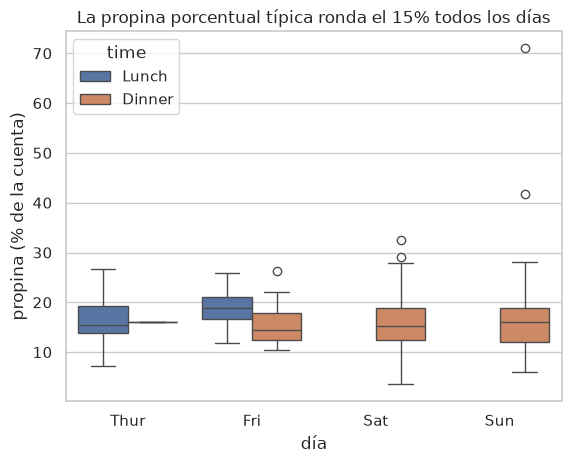

mean        median        count       
time Lunch Dinner  Lunch Dinner Lunch Dinner
day                                         
Thur  16.1   16.0   15.4   16.0  61.0    1.0
Fri   18.9   15.9   18.8   14.5   7.0   12.0
Sat    NaN   15.3    NaN   15.2   NaN   87.0
Sun    NaN   16.7    NaN   16.1   NaN   76.0

In [26]:
tabla_propinas = propinas.pivot_table(index="day", columns="time", values="tip_pct",
                                      aggfunc=["mean", "median", "count"]).round(1)
ax = sns.boxplot(propinas, x="day", y="tip_pct", hue="time")
ax.set(xlabel="día", ylabel="propina (% de la cuenta)",
       title="La propina porcentual típica ronda el 15% todos los días")
plt.show()
tabla_propinas

**✅ Respuesta sugerida:**

La propina porcentual típica ronda 15% a 16% en casi todas las combinaciones; el viernes en comida (media 18.9%) destaca, pero con solo 7 cuentas. La tabla está muy desbalanceada: el sábado y el domingo **no hay comidas**, el jueves hay una sola cena y el viernes solo 19 cuentas en total. Por eso "comida vs. cena" está confundido con el día (las comidas son casi todas de jueves) y cualquier comparación debe reportar el número de cuentas de cada celda.

### 🟢 Ejercicio 8 · Correlación y causalidad.

Para cada afirmación, indica si es correcta y, si no, cómo la reformularías:
1. "La correlación entre aleta y masa es 0.87, así que las aletas largas hacen que los pingüinos pesen más."
2. "Las mesas que piden en sábado dejan menos propina porcentual porque el sábado la gente es menos generosa."
3. "En el Titanic, viajar en primera clase se **asocia** con una mayor supervivencia; parte de esa asociación podría explicarse por la ubicación de los camarotes y la proporción de mujeres en cada clase."

**✅ Respuesta sugerida:**

1. **Incorrecta.** Es una asociación; ambas medidas reflejan el **tamaño corporal** (y la especie). Mejor: "aleta y masa están fuertemente asociadas (*r* ≈ 0.87); los pingüinos más grandes tienden a tener ambas mayores".
2. **Incorrecta.** La diferencia es pequeña, proviene de un solo mesero y no controla por el tamaño de la mesa, el horario ni el monto. Mejor: "en estos datos, la propina porcentual media del sábado fue algo menor (15.3% contra 16% a 17% otros días)".
3. **Correcta:** usa lenguaje de asociación y menciona posibles confusores.

### 🔴 Reto 4 · ¿Qué par de medidas separa mejor a las especies?

Dibuja `sns.pairplot` de las cuatro medidas coloreado por especie (con KDE en la diagonal). ¿Con qué par de variables se separarían las tres especies casi sin traslape? Justifica con la gráfica.

* La siguiente celda muestra una solución posible.

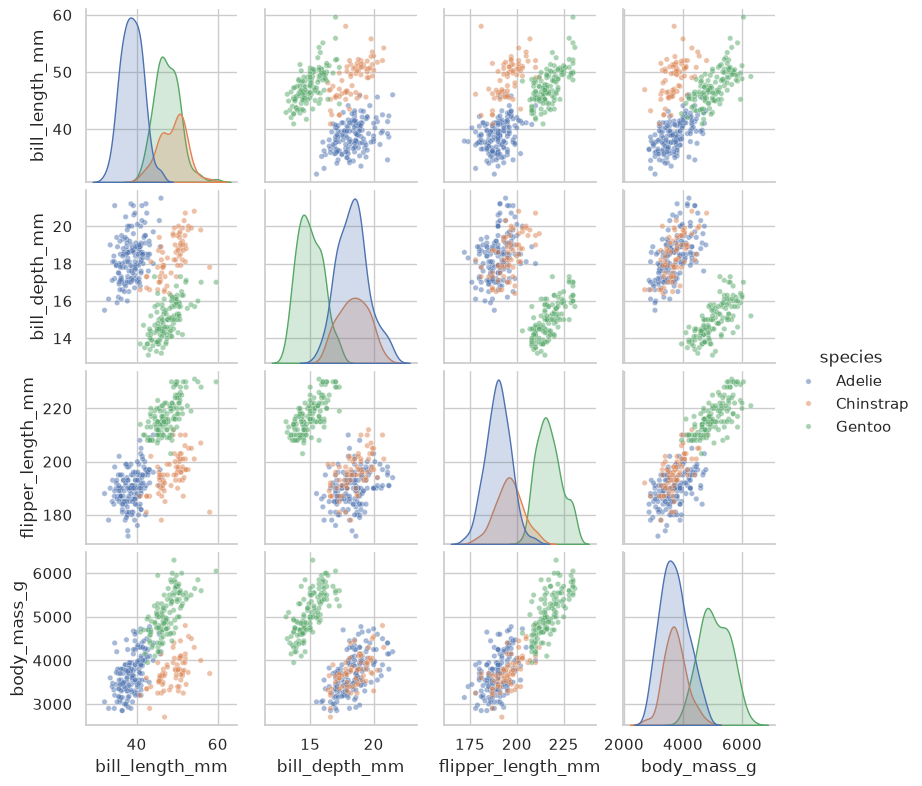

In [27]:
sns.pairplot(pinguinos[medidas + ["species"]], hue="species", diag_kind="kde", height=2,
             plot_kws={"alpha": 0.5, "s": 15})
plt.show()

**✅ Respuesta sugerida:**

Largo del pico contra profundidad del pico (o largo del pico contra aleta) separa las tres especies casi sin traslape: el largo distingue a Adelie (pico corto) de Chinstrap y Gentoo, y la profundidad o la aleta distinguen a Gentoo de Chinstrap. Ninguna variable por sí sola separa las tres especies.

---
## 5. Evaluación semanal 1 (10 min).

**Publicación:** hoy, jueves 22 de octubre, 8:30 pm · **Cierre:** domingo 25 de octubre, 11:59 pm (CDMX). Entregas tardías: hasta 48 h con 10% de penalización.

**Composición (100 puntos):**
* **Cuestionario (40 puntos):** Google Forms en modo examen, 10 preguntas de 4 puntos, un intento. Cubre los Módulos I y II.
* ***Notebook* (60 puntos):** tarea de Classroom con `eval1_eda_descriptivo.ipynb`. Se entrega el `.ipynb` **ejecutado** y el enlace al repositorio o *Codespace*.

**Consigna del *notebook*:** con `tips`, (1) auditar calidad y tipos de variables; (2) crear la variable `tip_pct`; (3) describir su distribución y sus atípicos; (4) comparar `tip_pct` por `day`, `time` y `smoker` con tablas agregadas; (5) producir 2 gráficas efectivas; (6) escribir 3 conclusiones descriptivas sin afirmaciones causales.

**Rúbrica del *notebook* (60 puntos):**

| Criterio | Puntos | Excelente |
|---|---|---|
| Calidad y tipos de variables | 10 | Auditoría completa (duplicados, faltantes, `dtypes`) y justificada |
| Descripción y atípicos | 12 | Medidas adecuadas a la forma de la distribución; atípicos identificados y discutidos |
| Agregación y comparación | 12 | Tablas correctas y bien elegidas para las 3 variables |
| Visualizaciones | 12 | Tipo adecuado, ejes y unidades rotulados, mensaje claro |
| Conclusiones | 8 | Respaldadas por los datos y sin lenguaje causal |
| Reproducibilidad | 6 | El *notebook* corre de principio a fin y está ordenado |

**Nota:** los *notebooks* 01 a 04 contienen todas las herramientas necesarias. Antes de entregar, conviene reiniciar el kernel y ejecutar todo (**Restart & Run All**) para comprobar que el *notebook* corre de principio a fin.

---
## ✅ Cierre.

**Hoy vimos:**
* Agregación con `groupby`/`agg` (agregaciones con nombre), `pivot_table`, `crosstab` y `melt`.
* Correlaciones de Pearson y Spearman, y cuándo difieren.
* Correlación no es causalidad: confusores y la **paradoja de Simpson** en los picos de los pingüinos.
* Visualización efectiva: elegir la gráfica, escalas honestas, facetas, color, rótulos y anotaciones, combinando *Matplotlib* y *Seaborn*.

**Práctica en Classroom:** la **Evaluación semanal 1** cierra el domingo 25 de octubre a las 11:59 pm (CDMX).

**Próxima sesión (lun 26 oct):** incertidumbre: muestreo, error estándar, intervalos de confianza y *bootstrap* (`05_incertidumbre_bootstrap.ipynb`). Se publica la consigna del Proyecto integrador.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>